<a href="https://colab.research.google.com/github/gawounnx/Data-Engineering-2026/blob/main/TIE_Fighter_202421246.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. my_utils.py 생성 (변환 함수 + 그리기 함수)

In [12]:
%%writefile my_utils.py
import numpy as np
from matplotlib.patches import Polygon

INF = 1000  # 그림판 크기
LEN = 100   # 처음 사각형의 크기


# ───────── 공통: 동차좌표 변환 ─────────
def apply(m, p):
    """3x3 변환행렬 m 을 2차원 점 p 에 적용 (실습Zero의 np.dot 이용)"""
    hp = np.array([p[0], p[1], 1.0])   # 1. 동차좌표로 변환
    q = np.dot(m, hp)                  # 2. 행렬 x 벡터
    return np.array([q[0], q[1]])      # 3. 2차원 좌표로 변환

Overwriting my_utils.py


In [13]:
%%writefile -a my_utils.py
# ───────── 1. 변환 함수 ─────────
def translate(p, dx, dy):          # 이동 T(dx, dy)
    m = np.array([[1.0, 0.0, dx], [0.0, 1.0, dy], [0.0, 0.0, 1.0]])
    return apply(m, p)

def rotate(p, theta):              # 회전 R(θ)
    c, s = np.cos(theta), np.sin(theta)
    m = np.array([[c, -s, 0.0], [s, c, 0.0], [0.0, 0.0, 1.0]])
    return apply(m, p)

def scale(p, sx, sy):              # 크기 S(sx, sy)
    m = np.array([[sx, 0.0, 0.0], [0.0, sy, 0.0], [0.0, 0.0, 1.0]])
    return apply(m, p)

def shear_x(p, sx):                # x축 방향 기울기 Shx(sx)
    m = np.array([[1.0, sx, 0.0], [0.0, 1.0, 0.0], [0.0, 0.0, 1.0]])
    return apply(m, p)

def shear_y(p, sy):                # y축 방향 기울기 Shy(sy)
    m = np.array([[1.0, 0.0, 0.0], [sy, 1.0, 0.0], [0.0, 0.0, 1.0]])
    return apply(m, p)

def reflect_x(p):                  # x축 대칭 (y → -y)
    m = np.array([[1.0, 0.0, 0.0], [0.0, -1.0, 0.0], [0.0, 0.0, 1.0]])
    return apply(m, p)

def reflect_y(p):                  # y축 대칭 (x → -x)
    m = np.array([[-1.0, 0.0, 0.0], [0.0, 1.0, 0.0], [0.0, 0.0, 1.0]])
    return apply(m, p)

def reflect_origin(p):             # 원점 대칭
    m = np.array([[-1.0, 0.0, 0.0], [0.0, -1.0, 0.0], [0.0, 0.0, 1.0]])
    return apply(m, p)

def reflect_yx(p):                 # y=x 대칭 (x ↔ y)
    m = np.array([[0.0, 1.0, 0.0], [1.0, 0.0, 0.0], [0.0, 0.0, 1.0]])
    return apply(m, p)


# 4개 꼭짓점에 같은 변환을 한 번에 적용하는 헬퍼 (가독성용)
def tf(points, func, *args):
    return [func(p, *args) for p in points]

Appending to my_utils.py


In [14]:
%%writefile -a my_utils.py
# ───────── 2. 그리기 기본 ─────────
def draw_axis(ax):
    ax.axhline(0, color='black', alpha=0.3)
    ax.axvline(0, color='black', alpha=0.3)
    ax.set_xlim(-INF, INF)
    ax.set_ylim(-INF, INF)
    ax.set_aspect('equal')

def draw_rectangle(ax, p1, p2, p3, p4, color='#555b66', edge='black'):
    ax.add_patch(Polygon([p1, p2, p3, p4], facecolor=color, edgecolor=edge, linewidth=1.5))


def centered(p1, p2, p3, p4):
    """사각형 중심을 원점으로: T(-LEN/2, -LEN/2)"""
    return tf([p1, p2, p3, p4], translate, -LEN/2, -LEN/2)

Appending to my_utils.py


In [15]:
%%writefile -a my_utils.py
# ───────── 3. TIE Fighter 파트 ─────────
def draw_cockpit(ax, p1, p2, p3, p4):
    # 정사각형 + 45° 회전 정사각형 → 팔각형(둥근 조종석)
    q = centered(p1, p2, p3, p4)
    q = tf(q, scale, 3.2, 3.2)               # S(3.2, 3.2)
    draw_rectangle(ax, *q)
    q = tf(q, rotate, np.pi/4)               # R(π/4)
    draw_rectangle(ax, *q)
    # 창문: 작은 팔각형
    w = tf(centered(p1, p2, p3, p4), scale, 1.6, 1.6)
    draw_rectangle(ax, *w, color='#1b1f27')
    draw_rectangle(ax, *tf(w, rotate, np.pi/4), color='#1b1f27')
    # 창문 살: 얇은 사각형을 회전 (0°, 45°, 90°, 135°)
    bar = tf(centered(p1, p2, p3, p4), scale, 1.7, 0.06)
    for k in range(4):
        draw_rectangle(ax, *tf(bar, rotate, k*np.pi/4), color='#555b66', edge='#555b66')

def draw_left_arm(ax, p1, p2, p3, p4):
    q = centered(p1, p2, p3, p4)
    q = tf(q, scale, 3.5, 0.6)               # 가로로 길고 얇게
    q = tf(q, translate, -330, 0)            # 왼쪽으로 이동
    draw_rectangle(ax, *q)

def draw_left_wing(ax, p1, p2, p3, p4):
    # 가운데 세로 기둥
    mid = tf(centered(p1, p2, p3, p4), scale, 0.5, 9)
    mid = tf(mid, translate, -520, 0)
    draw_rectangle(ax, *mid)
    # 위쪽 날개: 기울기(shear_x)로 안쪽으로 꺾음
    top = tf([p1, p2, p3, p4], scale, 0.5, 4)
    top = tf(top, translate, -25, 0)
    top = tf(top, shear_x, 0.45)
    top = tf(top, translate, -520, 450)
    draw_rectangle(ax, *top)
    # 아래쪽 날개: 위쪽을 x축 대칭
    bottom = tf(top, reflect_x)
    draw_rectangle(ax, *bottom)

def draw_right_arm(ax, p1, p2, p3, p4):
    # 왼쪽 날개축을 만든 뒤 y축 대칭
    q = centered(p1, p2, p3, p4)
    q = tf(q, scale, 3.5, 0.6)
    q = tf(q, translate, -330, 0)
    draw_rectangle(ax, *tf(q, reflect_y))

def draw_right_wing(ax, p1, p2, p3, p4):
    mid = tf(centered(p1, p2, p3, p4), scale, 0.5, 9)
    mid = tf(mid, translate, -520, 0)
    top = tf([p1, p2, p3, p4], scale, 0.5, 4)
    top = tf(top, translate, -25, 0)
    top = tf(top, shear_x, 0.45)
    top = tf(top, translate, -520, 450)
    bottom = tf(top, reflect_x)
    for part in (mid, top, bottom):          # 왼쪽 날개 전체를 y축 대칭
        draw_rectangle(ax, *tf(part, reflect_y))


def draw_object(ax):
    p1 = np.array([0, 0])
    p2 = np.array([LEN, 0])
    p3 = np.array([LEN, LEN])
    p4 = np.array([0, LEN])

    draw_left_arm(ax, p1, p2, p3, p4)     # 2. 왼쪽 날개축
    draw_right_arm(ax, p1, p2, p3, p4)    # 4. 오른쪽 날개축
    draw_left_wing(ax, p1, p2, p3, p4)    # 3. 왼쪽 날개
    draw_right_wing(ax, p1, p2, p3, p4)   # 5. 오른쪽 날개
    draw_cockpit(ax, p1, p2, p3, p4)      # 1. 중앙 조종석 (맨 위에 그리기)

Appending to my_utils.py


### 2. main

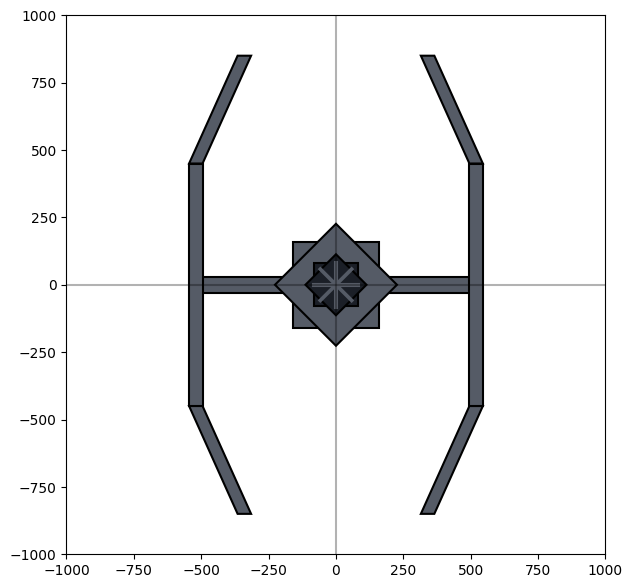

In [16]:
import matplotlib.pyplot as plt
from my_utils import draw_axis, draw_object

fig, ax = plt.subplots(figsize=(7, 7))
draw_axis(ax)
draw_object(ax)
plt.show()